# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos basados en Árboles**

* **Nombre:** Darío Martín Romero Cruz

* **Matrícula:** A01841015

# **Introducción: Auditoría de modelos de riesgo crediticio basados en Árboles**



### **Contexto del problema:**

* Una startup de tecnología financiera (fintech) llamada CrediNova busca fortalecer su proceso de evaluación de riesgo para créditos de consumo. Actualmente, la empresa recibe miles de solicitudes cada mes y desea anticipar cuáles clientes podrían incumplir sus obligaciones financieras durante los próximos 90 días.

* Dichos clientes ya tienen una relación vigente con la institución, con la cual ya poseen uno o más productos financieros activos. Se desea predecir, al momento de la evaluación (para otorgar o revisar un crédito), cuáles de dichos clientes caerán en incumplimiento de algunos de sus pagos durante los siguientes 90 días.

* Un analista junior del área de ciencia de datos bajo su propia iniciativa desarrolló la solución que se encuentra en este cuaderno de Jupyter, la cual está basada en modelos de árboles. Se dio a la tarea de conjuntar la información histórica con diversas áreas de la empresa y generar la base de datos que se encuentra en el archivo "fintech_default_risk.csv". Dicho archivo lo encuentras en Canvas.  

* Los resultados que se obtienen al ejecutar el código se ven bastante prometedores, tan es así, que el CEO desea autorizar su despliegue a producción lo antes posible. Sin embargo, la dirección de riesgos desea realizar antes una última validación de la propuesta. Siendo tú un científico de datos senior, te encargan realizar una auditoría forense de este cuaderno.  

* En particular, se espera que cumplas con los siguientes objetivos:

  * Puedes modificar el cuaderno (celdas de texto y código) tanto como lo consideres necesario, salvo donde se te indique.

  * Identificar y documentar al menos 6 errores conceptuales o metodológicos en la propuesta actual.
  
  * Detectar posibles fuentes de fuga de información (data leakage) tanto en los datos como en el proceso de ajuste y entrenamiento de los modelos.

  * Justificar el uso de la métrica, y en su caso, evaluar la pertinencia de proponer y usar otras métricas.

  * Identificar evidencia de sub o sobreentrenamiento con respecto a la métrica en cuestión.

  * Analizar el impacto de la selección del umbral de clasificación sobre los resultados del negocio.

  * Decidir cuál de los 3 modelos de árboles consideras el más adecuado para desplegar en producción.

  * Identificar los 3 o 4 factores más importantes del mejor modelo obtenido. Explicar sus significados en el contexto de negocio.

  * Realizar un reporte del resultado de la auditoría forense comprensible para los tomadores de decisiones. En particular, indicar si el modelo se puede desplegar en producción como lo propone el analista junior, o cuál serían en dado caso las recomendaciones.

  * Reportar las herramientas de IA generativa (LLMs) utilizadas como apoyo para la auditoría.
  

### **Descripción del negocio:**

* Cada vez que una solicitud de crédito es aprobada:
   * Si el cliente paga correctamente, la empresa obtiene una utilidad neta estimada de $100 USD.

   * Si el cliente entra en incumplimiento, la empresa enfrenta una pérdida promedio estimada de $500 USD.

* Por este motivo, el objetivo no consiste únicamente en maximizar métricas estadísticas, sino en maximizar el valor económico esperado para la organización. Por ello, como parte del análisis, también deberás estimar:
   * La utilidad esperada utilizando el umbral estándar de clasificación (0.5).

   * La utilidad esperada utilizando un umbral optimizado.
   
   * El impacto económico estimado por cada 10,000 solicitudes evaluadas.

# **Cargando y conociendo la información**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, roc_auc_score, average_precision_score,
                             recall_score, precision_score, f1_score, brier_score_loss)
from imblearn.over_sampling import SMOTE
from sklearn.inspection import permutation_importance

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier, DMatrix
import shap


RANDOM_STATE = 11   # No modificar el valor de esta semilla.
                    # Siempre que aparezca esta semilla, seguirla utilizando,
                    # inclusive con modelos o cualquier otra función o método.

In [2]:
# Cargamos los datos y obtenemos alguna información básica:

df = pd.read_csv('fintech_default_risk.csv')

print("Dimensión:", df.shape)
print("-"*25)
print('Variables involucradas:')
print(df.head(3).round(2).T)

print("\n")
print("-"*25)
print("Distribución objetivo:")
print(df["default_90d"].value_counts(normalize=True))


Dimensión: (5000, 14)
-------------------------
Variables involucradas:
                                     0         1         2
edad                             46.00     37.00     48.00
ingreso_mensual               34959.93   8659.83  11502.49
antiguedad_laboral_meses        296.00      6.00    166.00
score_crediticio                659.09    728.46    636.26
utilizacion_credito               0.41      0.88      0.41
atrasos_12m                       3.00      1.00      1.00
consultas_buro_6m                 5.00      2.00      3.00
num_productos                     7.00      3.00      1.00
limite_credito               209105.31  44070.50  42132.24
deuda_total                   77661.27  42105.84  15409.50
relacion_deuda_ingreso            2.22      4.86      1.34
dias_max_atraso_30d_despues       7.00      4.00      3.00
cliente_premium                   0.00      0.00      1.00
default_90d                       0.00      0.00      0.00


-------------------------
Distribución ob

In [3]:
print("Nulos:", df.isna().sum().sum(), "| Duplicados:", df.duplicated().sum())

print("\nCorrelación con el objetivo:")
print(df.corr()["default_90d"].drop("default_90d").sort_values(ascending=False).round(3))

print("\nRango de 'dias_max_atraso_30d_despues' por clase:")
print(df.groupby("default_90d")["dias_max_atraso_30d_despues"].agg(["min", "max"]))

Nulos: 0 | Duplicados: 0

Correlación con el objetivo:
dias_max_atraso_30d_despues    0.896
utilizacion_credito            0.231
relacion_deuda_ingreso         0.223
consultas_buro_6m              0.196
deuda_total                    0.165
atrasos_12m                    0.059
limite_credito                 0.033
ingreso_mensual                0.019
cliente_premium                0.007
num_productos                 -0.002
edad                          -0.006
antiguedad_laboral_meses      -0.016
score_crediticio              -0.152
Name: default_90d, dtype: float64

Rango de 'dias_max_atraso_30d_despues' por clase:
             min  max
default_90d          
0              0    9
1             15   89


**Fuga detectada**: `dias_max_atraso_30d_despues` se conoce después de la evaluación y, además, se observa que separa perfectamente las clases: quienes pagan tienen de 0 a 9 días de atraso y quienes incumplen, de 15 a 89. Se elimina.

In [4]:
df["antiguedad_laboral_years"] = df["antiguedad_laboral_meses"] / 12
I = df["antiguedad_laboral_years"] > df["edad"] - 10
print("Antigüedad laboral imposible para la edad:", I.sum())
print("\nEjemplos: ")
print(df.loc[I, ["edad", "antiguedad_laboral_meses", "antiguedad_laboral_years"]].round(2).head(10))
df.drop(columns = ["antiguedad_laboral_years"], inplace = True)

Antigüedad laboral imposible para la edad: 610

Ejemplos: 
    edad  antiguedad_laboral_meses  antiguedad_laboral_years
16    25                       249                     20.75
18    33                       283                     23.58
19    22                       190                     15.83
32    36                       337                     28.08
42    35                       335                     27.92
45    21                       250                     20.83
50    26                       324                     27.00
55    24                       278                     23.17
60    29                       308                     25.67
78    25                       310                     25.83


**Posible error en los datos**. Se observan 610 registros con antigüedad imposible: implican que el empleado inició a trabajar antes de los 10 años. Quizá sea porque son datos de prueba, pero en un escenario real esta información se debe validar con el área responsable.

In [5]:
# Definimos nuestras variables de entrada y la objetivo:

target = "default_90d"
fuga = ["dias_max_atraso_30d_despues"] # Información posterior a la evaluación (data leakage)

X = df.drop(columns=[target] + fuga)
y = df[target]

In [6]:
# Primero separamos Train y Test (estratificado, para conservar la proporción real ~11.7%).
# El Test queda intacto: representa a los clientes reales que llegarán en producción.

X_train_orig, X_test, y_train_orig, y_test = train_test_split(
    X,
    y,
    test_size=0.30,  # Partición 70%-30%.
    stratify=y,      # Misma proporción de incumplimiento en Train y Test.
    random_state=RANDOM_STATE  # semilla
)

# Debido al desbalanceo de clases, aplicamos SMOTE ÚNICAMENTE al conjunto de entrenamiento
# (aplicarlo antes del split filtra información del Test hacia el Train: data leakage).

smote = SMOTE(random_state=RANDOM_STATE   # semilla
              )

X_train, y_train = smote.fit_resample(X_train_orig, y_train_orig)

print("Train original :", X_train_orig.shape, y_train_orig.value_counts().to_dict())
print("Train con SMOTE:", X_train.shape, y_train.value_counts().to_dict())
print("Test (real)    :", X_test.shape, y_test.value_counts().to_dict())

Train original : (3500, 12) {0: 3090, 1: 410}
Train con SMOTE: (6180, 12) {0: 3090, 1: 3090}
Test (real)    : (1500, 12) {0: 1324, 1: 176}


**Comentario**: En esta celda se modifica la lógica. Antes el SMOTE se aplicaba en todos los datos. Ahora solo se aplica en el conjunto de entrenamiento.

# **Configuración y Entrenamiento de los Modelos**

In [7]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from imblearn.pipeline import Pipeline as ImbPipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# SMOTE va DENTRO del pipeline: en cada fold se aplica solo a la parte de entrenamiento,
# y los folds de validación conservan la proporción real de incumplimiento.
grids = {
    "Árbol de Decisión": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"modelo__max_depth": [3, 4, 5, 6, 8],
         "modelo__min_samples_leaf": [10, 25, 50, 100]}),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {"modelo__n_estimators": [300],
         "modelo__max_depth": [4, 6, 8, None],
         "modelo__min_samples_leaf": [5, 10, 25],
         "modelo__max_features": ["sqrt", 0.5]}),
    "XGBoost": (
        XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1),
        {"modelo__n_estimators": [200, 400],
         "modelo__max_depth": [2, 3, 4],
         "modelo__learning_rate": [0.03, 0.1],
         "modelo__subsample": [0.8],
         "modelo__colsample_bytree": [0.8],
         "modelo__min_child_weight": [1, 5]}),
}

modelos = {}
y_probs = []   # Probabilidades en Test: 0:DT, 1:RF, 2:XGBoost
resultados = []

for nombre, (modelo, grid) in grids.items():
    pipe = ImbPipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("modelo", modelo)
    ])
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv,
                      n_jobs=-1, return_train_score=True).fit(X_train_orig, y_train_orig)

    mejor = gs.best_estimator_
    modelos[nombre] = mejor.named_steps["modelo"]   # el modelo ya entrenado (para importancias/SHAP)

    p_test = mejor.predict_proba(X_test)[:, 1]
    y_probs.append(p_test)

    i = gs.best_index_
    resultados.append({
        "Modelo": nombre,
        "AUC Train (CV)": gs.cv_results_["mean_train_score"][i],
        "AUC Valid (CV)": gs.best_score_,
        "Std Valid": gs.cv_results_["std_test_score"][i],
        "AUC Test": roc_auc_score(y_test, p_test),
        "PR-AUC Test": average_precision_score(y_test, p_test),
    })
    print(f"{nombre}: {gs.best_params_}")

print("")
display(pd.DataFrame(resultados).set_index("Modelo").round(4))
print("\nReferencia: AUC azar = 0.5 | PR-AUC azar =", round(y_test.mean(), 4))

dt = modelos["Árbol de Decisión"]
rf = modelos["Random Forest"]
xgb = modelos["XGBoost"]

Árbol de Decisión: {'modelo__max_depth': 6, 'modelo__min_samples_leaf': 100}
Random Forest: {'modelo__max_depth': 4, 'modelo__max_features': 0.5, 'modelo__min_samples_leaf': 25, 'modelo__n_estimators': 300}
XGBoost: {'modelo__colsample_bytree': 0.8, 'modelo__learning_rate': 0.03, 'modelo__max_depth': 2, 'modelo__min_child_weight': 5, 'modelo__n_estimators': 200, 'modelo__subsample': 0.8}



,AUC Train (CV),AUC Valid (CV),Std Valid,AUC Test,PR-AUC Test
Modelo,,,,,
Árbol de Decisión,0.7926,0.7431,0.0303,0.7362,0.2992
Random Forest,0.8142,0.7604,0.0339,0.7646,0.3211
XGBoost,0.8035,0.7481,0.0279,0.7659,0.3182



Referencia: AUC azar = 0.5 | PR-AUC azar = 0.1173


**Sobreentrenamiento detectado**: con hiperparámetros por defecto, los tres modelos obtienen accuracy de 1.0 en train y de 0.73–0.83 en test, por debajo de la referencia trivial de 0.883 (“nadie incumple”). En AUC, el árbol cae a 0.59 en test. Los modelos memorizaban el entrenamiento, incluidos los clientes sintéticos de SMOTE. 

**Corrección**: se limitan la profundidad y el tamaño mínimo de las hojas, y se eligen con validación cruzada estratificada de 5 folds y SMOTE dentro de un pipeline. La métrica es *ROC-AUC* en lugar de *accuracy*, por el desbalance. La diferencia entre train y validación baja a ~0.05 y el AUC de validación coincide con el de test. *PR-AUC* se reporta porque se concentra en la clase minoritaria (su referencia al azar es 0.117, no 0.5). La métrica final de decisión es la utilidad económica.

**Mejor modelo**: Se observa que los 3 modelos tienen valores muy cercanos entre sí. En particular, Random Forest obtiene un AUC de validación ligeramente mayor (0.760), pero la diferencia es menor que la variación entre folds (+/- 0.03) por lo que no es estadísticamente superior. Por otro lado, XGBoost es el más estable de los 3, con una desviación de 0.028; su AUC de test es el más alto (0.766).

Como el objetivo es económico, el desempate se hace con la utilidad en validación (ver sección de negocio), donde XGBoost es ligeramente superior. Se selecciona **XGBoost**.

# **Importancia e Interpretabilidad de los Factores o Características:**

**En realidad solo debiéramos hacer el análisis de los mejores factores para el mejor modelo encotrado, pero como todos resultaron con el mejor desempeño, incluímos los tres casos a continuación como referencia.**

In [8]:
# Modelo de Árbol de Decisión (decision tree-dt):

# Creamos el DataFrame para ordenarlas y visualizarlas mejor:
df_importancias = pd.DataFrame({
    'Característica': X_train.columns,
    'Importancia': dt.feature_importances_
}).sort_values(by='Importancia', ascending=False)

print(df_importancias.round(4))

              Característica  Importancia
4        utilizacion_credito       0.5061
6          consultas_buro_6m       0.1669
3           score_crediticio       0.1662
11           cliente_premium       0.0777
7              num_productos       0.0333
10    relacion_deuda_ingreso       0.0302
8             limite_credito       0.0118
9                deuda_total       0.0061
0                       edad       0.0017
1            ingreso_mensual       0.0000
2   antiguedad_laboral_meses       0.0000
5                atrasos_12m       0.0000


In [9]:
# Modelo Bosque Aleatorio (Random Forest-rf):

importancias = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia (impureza)": rf.feature_importances_,
    "Importancia (permutación AUC)": permutation_importance(
        rf, X_test, y_test, scoring="roc_auc", n_repeats=20,
        random_state=RANDOM_STATE).importances_mean
}).sort_values("Importancia (permutación AUC)", ascending=False)

display(importancias.head(10).round(4))

,Variable,Importancia (impureza),Importancia (permutación AUC)
4,utilizacion_credito,0.4045,0.0894
3,score_crediticio,0.1490,0.0624
6,consultas_buro_6m,0.1392,0.0468
10,relacion_deuda_ingreso,0.1465,0.0113
7,num_productos,0.0497,0.0020
11,cliente_premium,0.0545,0.0010
1,ingreso_mensual,0.0058,0.0004
8,limite_credito,0.0045,0.0004
2,antiguedad_laboral_meses,0.0089,0.0004
0,edad,0.0079,0.0001


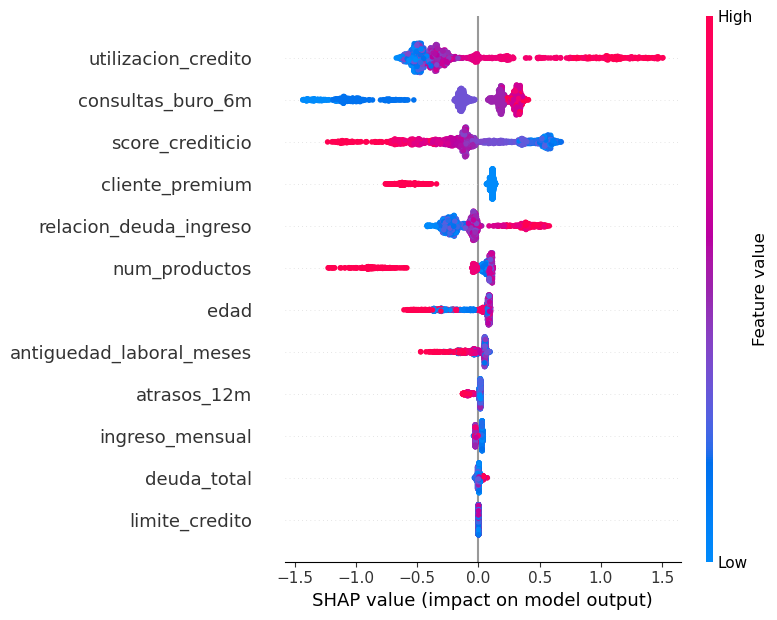

In [10]:
# Modelo XGBoost:

# SHAP nativo de XGBoost (evita la incompatibilidad shap 0.48 / xgboost 3.x).
# La última columna es el valor base E[f(X)] en escala log-odds.
contribs = xgb.get_booster().predict(DMatrix(X_test), pred_contribs=True)
shap_values = contribs[:, :-1]
expected_value = contribs[0, -1]

shap.summary_plot(shap_values, X_test)

**Factores más importantes** (XGBoost, SHAP): los cuatro factores principales coinciden en los tres modelos.
* Utilización de crédito: a mayor uso de la línea, más riesgo; el incumplimiento sube de 5.8% a 25.2%. Indica estrés de liquidez.
* Consultas al buró (6 meses): de 6.6% a 22% con 5 consultas o más. Indica que el cliente busca crédito en varias instituciones.
* Score crediticio: a mayor score, menos riesgo; 21% de incumplimiento en el cuartil bajo contra 7.5% en el alto. Refleja el historial de pago.
* Relación deuda-ingreso: de 6.2% a 22.1% cuando la deuda supera 2.5 veces el ingreso mensual. Mide la capacidad de pago.

`cliente_premium` y `num_productos` aparecen en la gráfica, pero puede ser efecto de SMOTE, que trunca las variables discretas al crear clientes sintéticos. En los datos reales no presentaban correlación con el incumplimiento.

## **Seleccionemos y analicemos un cliente en Particular:**

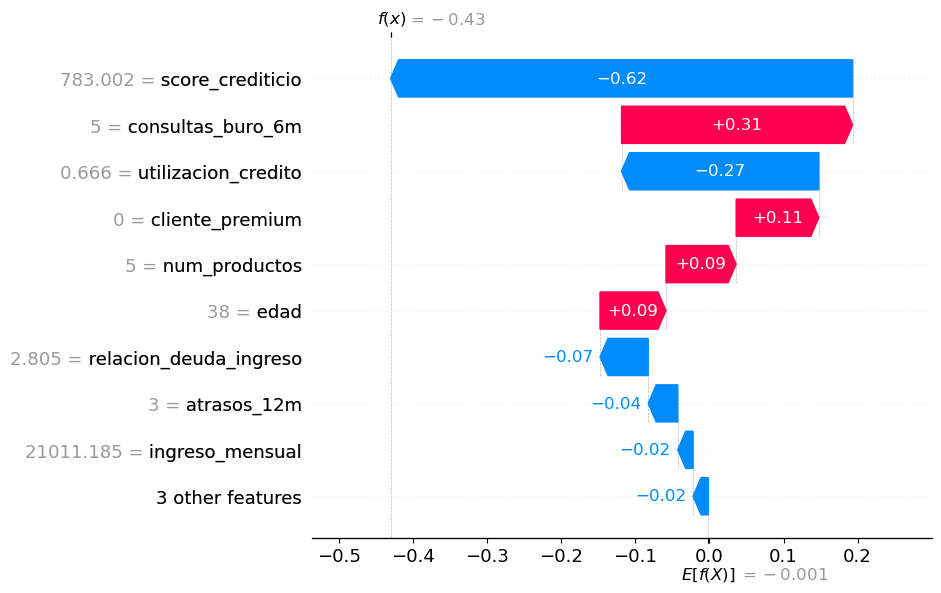

Probabilidad de incumplimiento: 0.394 | Real: 0


In [11]:
# Analicemos a un cliente en particular con XGBoost:
idx = 11
cliente = X_test.iloc[[idx]] # cliente real (el test ya no contiene registros sintéticos)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[idx],
        base_values=expected_value,
        data=cliente.iloc[0],
        feature_names=list(cliente.columns)
    )
)

print("Probabilidad de incumplimiento:", round(xgb.predict_proba(cliente)[0, 1], 3),
      "| Real:", y_test.iloc[idx])

**Interpretación del gráfico:**

El cliente parte del valor base E[f(X)] ≈ -0.001 (log-odds), que equivale a una probabilidad de ~0.50 (promedio de un entrenamiento balanceado con SMOTE). Termina en f(x) ≈ −0.43, que equivale a una probabilidad de incumplimiento de 0.394.

Suben el riesgo: 
* 5 consultas al buró en 6 meses (0.31). Puede indicar que está buscando financiamiento en otras instituciones.
* No es cliente premium (0.11). Posible efecto de SMOTE.
* Número de productos y edad (0.09).

Bajan el riesgo: 
* Score crediticio alto de 783 (−0.62). Representa buen historial de pagos.
* Utilización de crédito de 0.667 (-0.27). Justo por debajo del umbral de alto riesgo.

Con el umbral estándar de 0.5 el cliente se aprueba (0.394 < 0.5). En la realidad no incumplió (`default_90d` = 0), así que la decisión fue correcta.

# **Análisis desde la perspectiva del negocio:**

In [12]:
GANANCIA_BUENO = 100
PERDIDA_DEFAULT = -500


In [13]:
# Función de utilidad:

# Considerando el umbral estándar:
threshold = 0.5

def utilidad(y_true, y_prob, threshold):

    aprobar = y_prob < threshold

    utilidad_total = 0

    for real, aprobado in zip(y_true, aprobar):

        if aprobado:

            if real == 0:
                utilidad_total += GANANCIA_BUENO

            else:
                utilidad_total += PERDIDA_DEFAULT

    return utilidad_total



# Mejor modelo encontrado:
idx_mejor = 2   # XGBoost
nombre_mejor = list(modelos)[idx_mejor]
y_probs_mejor_modelo = y_probs[idx_mejor]

utilidad_05 = utilidad(y_test, y_probs_mejor_modelo, threshold=0.5)

# Referencia: sin modelo (se aprueba a todos los solicitantes):
utilidad_todos = utilidad(y_test, np.zeros(len(y_test)), threshold=0.5)

print(f"Utilidad en Test (USD) con umbral 0.5 ({nombre_mejor}): ${utilidad_05:,}")
print(f"Utilidad en Test (USD) sin modelo (aprobar a todos): ${utilidad_todos:,}")

Utilidad en Test (USD) con umbral 0.5 (XGBoost): $68,000
Utilidad en Test (USD) sin modelo (aprobar a todos): $44,400


**Cambios**: la función original tenía los valores 100 y −500 escritos directamente en lugar de usar las constantes definidas. Además, ahora la utilidad se calcula sobre un Test con clientes reales y la proporción real de incumplimiento (11.7%). En la versión original, el Test tenía 50% de clientes sintéticos de SMOTE, así que la utilidad no representaba al negocio. Se agrega como referencia la estrategia “sin modelo” (aprobar a todos), para medir cuánto valor aporta el modelo.

Mejor umbral (elegido en validación): 0.63
Utilidad en Test con ese umbral (USD): $64,000
Umbral teórico ajustado por SMOTE: 0.60


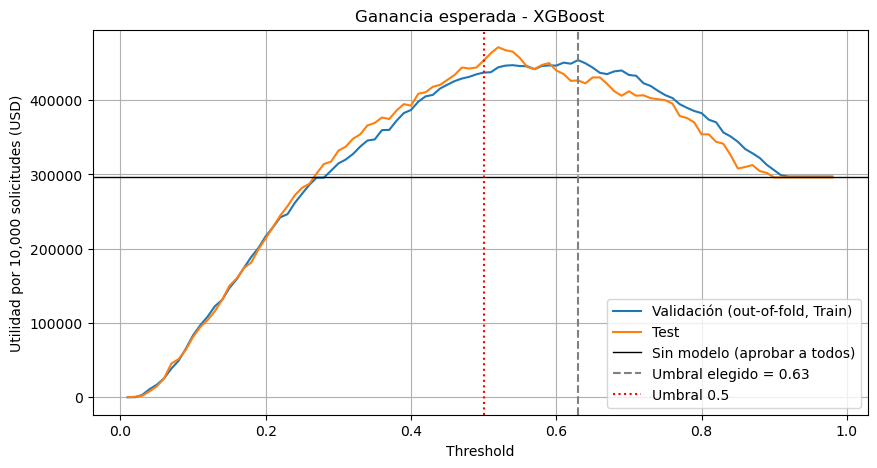

In [14]:
# Ajustando para buscar el mejor umbral óptimo.
# IMPORTANTE: el umbral se elige con predicciones out-of-fold del conjunto de
# entrenamiento (validación cruzada, con SMOTE dentro del pipeline), NO con el Test.
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

thresholds = np.arange(0.01, 0.99, 0.01)

y_oof = []   # Probabilidades out-of-fold en Train: 0:DT, 1:RF, 2:XGBoost
for nombre, modelo in modelos.items():
    pipe = ImbPipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("modelo", clone(modelo))   # mismos hiperparámetros, sin entrenar
    ])
    y_oof.append(cross_val_predict(pipe, X_train_orig, y_train_orig,
                                   cv=cv, method="predict_proba")[:, 1])

utilidades_cv = [utilidad(y_train_orig, y_oof[idx_mejor], th) for th in thresholds]
best_idx = np.argmax(utilidades_cv)
best_threshold = thresholds[best_idx]

# Solo como referencia (no se usa para elegir), la curva en Test:
utilidades_test = [utilidad(y_test, y_probs_mejor_modelo, th) for th in thresholds]
best_profit = utilidad(y_test, y_probs_mejor_modelo, best_threshold)

print(f"Mejor umbral (elegido en validación): {best_threshold:.2f}")
print(f"Utilidad en Test con ese umbral (USD): ${best_profit:,}")

# Umbral teórico: aprobar si 100(1-p) - 500p > 0  ->  p < 1/6 (con la proporción real).
# Como SMOTE entrenó con 50%-50%, se ajusta a la escala del modelo:
w = (y_train_orig == 0).sum() / (y_train_orig == 1).sum()       # ~7.5 = cuánto se inflaron los momios
odds_teorico = (1/6) / (1 - 1/6) * w
umbral_teorico = odds_teorico / (1 + odds_teorico)
print(f"Umbral teórico ajustado por SMOTE: {umbral_teorico:.2f}")

# Grafiquemos Umbral vs Utilidad (por cada 10,000 solicitudes):
plt.figure(figsize=(10, 5))
plt.plot(thresholds, np.array(utilidades_cv) / len(y_train_orig) * 10_000, label="Validación (out-of-fold, Train)")
plt.plot(thresholds, np.array(utilidades_test) / len(y_test) * 10_000, label="Test")
plt.axhline(utilidad_todos / len(y_test) * 10_000, color="black", lw=1, label="Sin modelo (aprobar a todos)")
plt.axvline(best_threshold, ls="--", color="gray", label=f"Umbral elegido = {best_threshold:.2f}")
plt.axvline(0.5, ls=":", color="red", label="Umbral 0.5")
plt.xlabel("Threshold")
plt.ylabel("Utilidad por 10,000 solicitudes (USD)")
plt.title(f"Ganancia esperada - {nombre_mejor}")
plt.legend()
plt.grid()
plt.show()

**Selección del umbral**: el notebook original buscaba el umbral óptimo sobre el propio Test. Así, el Test deja de ser una medición independiente y la utilidad reportada es optimista. Ahora el umbral se elige con predicciones out-of-fold del entrenamiento: 0.63.

**Validación teórica**: conviene aprobar si `100(1 − p) − 500p > 0`, es decir, `p < 1/6`. Como SMOTE infló las probabilidades (promedio 0.38 contra una tasa real de 0.117), al ajustar 1/6 a la escala del modelo se obtiene 0.60, consistente con el 0.63 encontrado en validación.

**Forma de la curva**: en validación es casi plana entre 0.55 y 0.65 (de \$444k a \$447k por cada 10k). Cualquier umbral en ese rango da prácticamente la misma utilidad.

In [15]:
# Calculamos ahora la utilidad por cada 10,000 solicitudes:


def utilidad_por_10000(y_true, y_prob, threshold):

    aprobados = y_prob < threshold

    utilidad = 0
    total_aprobados = 0

    for real, aprobado in zip(y_true, aprobados):

        if aprobado:

            total_aprobados += 1

            if real == 0:
                utilidad += GANANCIA_BUENO

            else:
                utilidad += PERDIDA_DEFAULT

    # Escalamos a 10,000 solicitudes:
    utilidad_escalada = utilidad * (
        10_000 / len(y_true)
    )

    return utilidad_escalada



In [16]:
profit_todos = utilidad_por_10000(y_test, np.zeros(len(y_test)), threshold=0.5)

profit_default = utilidad_por_10000(y_test, y_probs_mejor_modelo, threshold=0.50)

profit_optimal = utilidad_por_10000(y_test, y_probs_mejor_modelo, threshold=best_threshold)

delta = profit_optimal - profit_default

incremento_pct = (delta / abs(profit_default)) * 100

print(f"Sin modelo (aprobar a todos) : ${profit_todos:,.0f}")
print(f"Threshold 0.50               : ${profit_default:,.0f}")
print(f"Threshold óptimo ({best_threshold:.2f})      : ${profit_optimal:,.0f}")
print(f"Diferencia vs 0.50           : ${delta:,.0f} ({incremento_pct:.1f}%)")
print(f"Diferencia vs sin modelo     : ${profit_default - profit_todos:,.0f} (umbral 0.5) | "
      f"${profit_optimal - profit_todos:,.0f} (umbral óptimo)")

# ¿La diferencia entre umbrales es real o ruido? Intervalo bootstrap al 95%:
rng = np.random.default_rng(RANDOM_STATE)
y_arr = np.asarray(y_test)
difs = []
for _ in range(1000):
    i = rng.integers(0, len(y_arr), len(y_arr))
    difs.append(utilidad_por_10000(y_arr[i], y_probs_mejor_modelo[i], best_threshold)
                - utilidad_por_10000(y_arr[i], y_probs_mejor_modelo[i], 0.5))
print(f"IC 95% de la diferencia (óptimo - 0.5): ${np.percentile(difs, 2.5):,.0f} a ${np.percentile(difs, 97.5):,.0f}")

# Comparación de los 3 modelos (cada uno con su umbral elegido en validación):
filas = []
for k, nombre in enumerate(modelos):
    u_cv = [utilidad(y_train_orig, y_oof[k], th) for th in thresholds]
    th_k = thresholds[np.argmax(u_cv)]
    y_pred_k = (y_probs[k] >= th_k).astype(int)
    filas.append({
        "Modelo": nombre,
        "Umbral": round(th_k, 2),
        "Utilidad validación /10k": max(u_cv) / len(y_train_orig) * 10_000,
        "Utilidad Test 0.5 /10k": utilidad_por_10000(y_test, y_probs[k], 0.5),
        "Utilidad Test óptimo /10k": utilidad_por_10000(y_test, y_probs[k], th_k),
        "Recall": recall_score(y_test, y_pred_k),
        "Precisión": precision_score(y_test, y_pred_k),
        "% Aprobados": (y_pred_k == 0).mean(),
    })
display(pd.DataFrame(filas).set_index("Modelo").round(3).T)

Sin modelo (aprobar a todos) : $296,000
Threshold 0.50               : $453,333
Threshold óptimo (0.63)      : $426,667
Diferencia vs 0.50           : $-26,667 (-5.9%)
Diferencia vs sin modelo     : $157,333 (umbral 0.5) | $130,667 (umbral óptimo)
IC 95% de la diferencia (óptimo - 0.5): $-68,733 a $14,000


Modelo,Árbol de Decisión,Random Forest,XGBoost
Umbral,0.540,0.570,0.630
Utilidad validación /10k,446285.714,452857.143,454000.000
Utilidad Test 0.5 /10k,376666.667,452000.000,453333.333
Utilidad Test óptimo /10k,426666.667,442000.000,426666.667
Recall,0.580,0.489,0.392
Precisión,0.245,0.290,0.317
% Aprobados,0.723,0.802,0.855


**Observaciones**:
* El modelo genera valor: con cualquiera de los dos umbrales, la utilidad sube entre \$130k y \$157k por cada 10,000 solicitudes frente a no usarlo, porque evita aprobar a buena parte de los clientes que incumplen.
* Entre los dos umbrales no hay diferencia significativa: en Test, 0.63 rinde \$26,667 menos que 0.5, pero el intervalo de confianza del 95% (−\$68,733 a \$14,000) incluye el cero. Es ruido de muestra, la curva de utilidad es plana en esa zona. Elegir 0.52, el máximo en Test (\$471k), sería repetir el error del analista.
* El umbral es una decisión de apetito de riesgo: 0.5 aprueba al 73% de los solicitantes y detecta al 61% de los incumplidos. 0.63 aprueba al 85% (más volumen y más clientes atendidos) y detecta al 39%. La utilidad es similar, así que la elección depende de la estrategia comercial. Un punto intermedio (~0.55–0.60) es razonable y lo respalda el umbral teórico (0.60).
* Corrección del análisis original: el analista reportaba ~\$500,944 por cada 10k con incremento de 0%, calculado sobre un Test con 50% de clientes sintéticos y con la variable con fuga. Esa cifra no era real.

## **Matriz de Confusión**



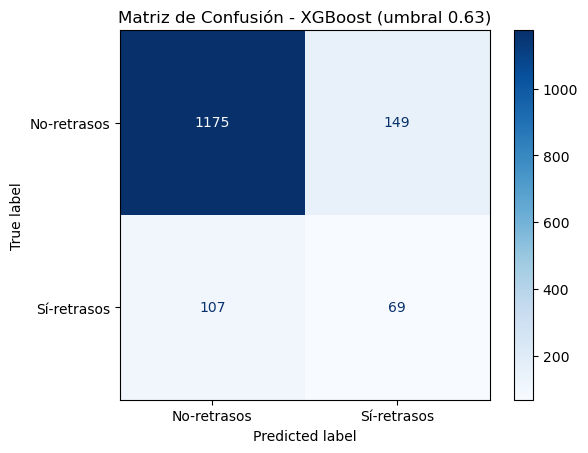

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

class_names = ["No-retrasos", "Sí-retrasos"]
y_pred = (y_probs_mejor_modelo >= best_threshold).astype(int)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, cmap=plt.cm.Blues
)
plt.title(f"Matriz de Confusión - {nombre_mejor} (umbral {best_threshold:.2f})")
plt.show()

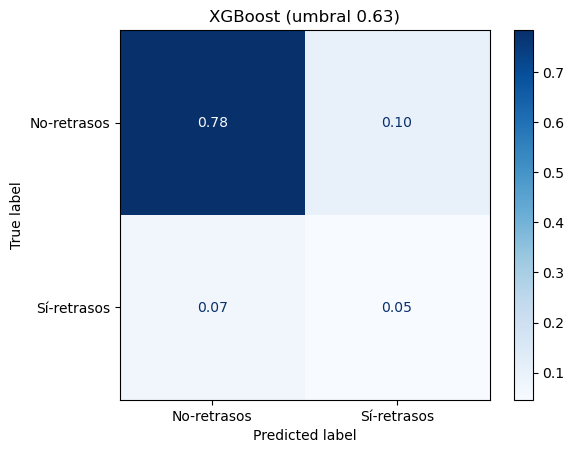

In [18]:
# O bien en su forma de proporciones:
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize='all',  # Normalizando con respecto al total de datos.
    values_format='.2f' # Total de decimales desplegadas.
)
plt.title(f"{nombre_mejor} (umbral {best_threshold:.2f})")
plt.show()

**Correcciones**: la versión original usaba las variables modelo y nombre que quedaban del bucle de entrenamiento (era XGBoost por casualidad) y predict() con umbral 0.5, sin relación con el umbral del análisis de negocio. Ahora se usa explícitamente el mejor modelo con el umbral elegido.

Lectura (umbral 0.63, 1,500 clientes de Test):

* 1,175 clientes buenos aprobados (verdaderos negativos): generan la utilidad.
* 149 clientes buenos rechazados (falsos positivos): utilidad perdida, \$100 cada uno.
* 107 incumplidos aprobados (falsos negativos): el error más caro, \$500 cada uno.
* 69 incumplidos detectados (verdaderos positivos): pérdidas evitadas.

Con umbral 0.5 la matriz cambia a 1,025 / 299 / 69 / 107: se detectan más incumplidos, pero se rechazan el doble de buenos clientes. Esto muestra el intercambio entre volumen y riesgo descrito arriba.

# **Conclusiones particulares:**



**Incluye un reporte de los resultados obtenidos dirigido al CEO de la fintech con las sugerencias y conclusiones en relación a cuál modelo desplegar.**

### +++++++++++ Inicia sección de Conclusiones Particulares ++++++++++++++++

## Reporte de auditoría: modelo de riesgo de incumplimiento a 90 días

**Para:** Dirección General de CrediNova

**Asunto:** Viabilidad del modelo propuesto para su despliegue en producción
<br><br>

**1. Dictamen**

**No se recomienda desplegar el modelo tal como fue propuesto.** Sus resultados (100% de precisión y una utilidad de ~\$500,944 por cada 10,000 solicitudes) no son reales: se deben a errores en los datos y en la forma de evaluar el modelo. **Una vez corregido, el modelo sí genera valor** y puede avanzar a una **prueba piloto controlada**.
<br><br>

**2. Qué estaba mal (en términos de negocio)**

* **El modelo "conocía el futuro":** usaba el atraso del cliente en los 30 días *posteriores* a la evaluación, un dato que no existe al momento de decidir. Con él, el modelo parecía perfecto; sin él, ese desempeño desaparece.
* **Se evaluó con clientes ficticios:** la técnica de balanceo (SMOTE) se aplicó antes de separar los datos. El examen final incluía clientes sintéticos "parecidos" a los de entrenamiento y una tasa de incumplimiento de 50%, cuando la real es 11.7%.
* **Memorizaba en lugar de aprender:** sin límites de complejidad, los modelos memorizaban los datos de entrenamiento. Sin la fuga, su desempeño en clientes nuevos caía por debajo de la estrategia trivial de "aprobar a todos".
* **La utilidad y el umbral se calcularon sobre el mismo examen**, lo que infla los resultados.
<br><br>

**3. Resultados del modelo corregido (XGBoost)**

Evaluado con 1,500 clientes reales que el modelo nunca vio:

| Estrategia | Utilidad por cada 10,000 solicitudes | vs. sin modelo |
|---|---|---|
| Sin modelo (aprobar a todos) | \$296,000 | — |
| Modelo, umbral 0.50 | \$453,333 | **+\$157,333 (+53%)** |
| Modelo, umbral 0.63 | \$426,667 | +\$130,667 (+44%) |

* **Capacidad de discriminación:** AUC de 0.77. Es un desempeño razonable para riesgo de consumo y, a diferencia del 100% original, creíble.
* **Elección del modelo:** los tres modelos evaluados (árbol, Random Forest y XGBoost) tienen un desempeño similar. Se elige **XGBoost** por obtener la mayor utilidad en validación y ser el más estable.
* **El umbral es una decisión de apetito de riesgo, no solo técnica:**
  * Con **0.50** se aprueba al 73% de los solicitantes y se detecta al 61% de los incumplidos;
  * Con **0.63** se aprueba al 85% (más volumen) y se detecta al 39%.

  La utilidad es estadísticamente equivalente entre ambos. Se recomienda un punto intermedio (**0.55–0.60**), respaldado también por el umbral teórico de costo-beneficio: un incumplimiento cuesta lo mismo que la ganancia de 5 buenos clientes.
<br><br>

**4. Qué señales de riesgo identifica el modelo**

1. **Uso alto de las líneas de crédito:** el incumplimiento sube de 6% a 25%.
2. **Muchas consultas recientes al buró:** de 7% a 22%. Indica búsqueda de financiamiento en otras instituciones.
3. **Score crediticio bajo:** 21% contra 7.5% en los scores altos.
4. **Deuda alta respecto al ingreso:** de 6% a 22%.

Son factores coherentes con la práctica de crédito, lo que da confianza en el modelo y facilita explicar sus decisiones a clientes y reguladores.
<br><br>

**5. Recomendaciones**

1. **Desplegar la versión corregida solo como piloto:** aplicarla a un porcentaje de las solicitudes durante 3 meses y comparar la utilidad real contra el proceso actual (*champion/challenger*).
2. **Gobierno de datos:** validar que cada variable esté disponible al momento de decidir y corregir los registros inconsistentes con las áreas responsables.
3. **Mejorar el balanceo de clases:** SMOTE generó efectos artificiales (por ejemplo, el segmento premium parece relevante sin serlo). Evaluar pesos por clase o SMOTENC antes del despliegue definitivo.
4. **Validar con datos de un periodo posterior** al de entrenamiento antes de escalar.
5. **Definir el umbral con Riesgos y Comercial**, según la estrategia de volumen frente a riesgo, y revisarlo periódicamente.
6. **Monitorear en producción:** tasa real de incumplimiento, utilidad, estabilidad de las variables y reentrenamiento periódico.
7. **Cumplimiento:** revisar el uso de variables sensibles como la edad.
<br><br>

**En resumen:** el modelo original no es confiable, pero la oportunidad es real. La versión corregida aumenta la utilidad en aproximadamente **\$130,000–\$157,000 por cada 10,000 solicitudes** frente a no usar modelo, y conviene confirmarlo con un piloto antes de su adopción total.

### +++++++++++ Termina sección de conclusiones particulares ++++++++++++++

# **Conclusiones**

Incluye todos los comentarios y conclusiones de esta actividad. En particular, responde sobre los siguientes puntos:

* Indica en qué casos el uso de LLMs fue de mayor provecho.
* En cuáles casos tu intervención como experto en combinación con los LLM fue importante para alcanzar con los objetivos propuestos.


### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++

**1. Resumen de la auditoría**

El notebook del analista junior reportaba un desempeño perfecto (*accuracy* de 1.0 en train y en test para los tres modelos) y una utilidad de ~\$500,944 por cada 10,000 solicitudes. La auditoría mostró que esos resultados se debían a **fugas de información y errores de evaluación**, no a la calidad del modelo. Una vez corregidos, los modelos alcanzan un *AUC* de ~0.77 en clientes no vistos. El desempeño es mucho más modesto, pero real, y el modelo sigue aportando valor económico: entre **+\$130k y +\$157k por cada 10,000 solicitudes** frente a no usar modelo.
<br><br>

**2. Errores identificados**

1. **Fuga de datos:** `dias_max_atraso_30d_despues` es información posterior a la evaluación y separaba las clases a la perfección. Se eliminó.
2. **SMOTE antes del split:** había clientes sintéticos en el test, con una tasa de incumplimiento artificial de 50%. Ahora SMOTE se aplica solo en train, dentro del pipeline.
3. ***Accuracy* como métrica:** con clases desbalanceadas, "nadie incumple" ya da 0.883. Se reemplazó por *ROC-AUC*, *PR-AUC* y utilidad económica.
4. **Sobreajuste:** con hiperparámetros por defecto, train daba 1.0 y test 0.73–0.83. Se corrigió con GridSearchCV y validación cruzada estratificada.
5. **SMOTE trunca variables discretas:** `cliente_premium` aparece como factor de riesgo sin serlo. Se recomienda explorar la opción de usar SMOTENC o pesos por clase.
6. **Interpretación inválida del cliente:** se basaba en la variable con fuga. Se explica un cliente real con el modelo corregido.
7. **Utilidad mal calculada:** se calculaba sobre un test con SMOTE y con valores escritos directamente en la función. Ahora se usa el test real, las constantes y la referencia "sin modelo".
8. **Umbral elegido sobre el test:** ahora se elige con predicciones out-of-fold y se valida con el umbral teórico (0.60).
9. **Matriz de confusión incorrecta:** usaba variables sobrantes del bucle y el umbral 0.5. Ahora usa el modelo y el umbral explícitos.

Además, hay **610 registros con antigüedad laboral imposible** que deben validarse con las áreas responsables.
<br><br>

**3. Aprendizajes principales**
* **Un resultado perfecto es una señal de alarma, no un logro.** En riesgo de crédito, un *AUC* de 0.75–0.85 es bueno; un 100% casi siempre indica fuga.
* **La fuga no se evita solo separando train y test.** También ocurre por variables del futuro, por transformaciones aplicadas antes del split y por decisiones tomadas mirando el test.
* **El test se usa una sola vez.** Hiperparámetros, umbral y elección del modelo deben decidirse con validación cruzada.
* **La métrica debe reflejar el negocio.** Con costos asimétricos (un incumplimiento cuesta lo mismo que 5 buenos clientes), la decisión final se toma con la utilidad, no con la *accuracy*.
* **Las diferencias pequeñas deben ponerse a prueba.** Los tres modelos y los umbrales de 0.50 a 0.63 resultaron estadísticamente equivalentes. Reportar ese empate es mejor que declarar un ganador artificial.
* **Las técnicas de balanceo tienen efectos secundarios.** SMOTE infla las probabilidades (promedio de 0.38 contra una tasa real de 0.117) y crea relaciones falsas en variables discretas. Hay que entender cómo funciona una técnica antes de aplicarla.
<br><br>

**4. Uso de IA generativa (LLMs)**

**Herramienta utilizada:** Claude (Anthropic), mediante Claude Code.

Dónde fue de mayor provecho:
* **Generación de código:** pipeline con SMOTE dentro de la validación cruzada, búsqueda de hiperparámetros, predicciones out-of-fold, bootstrap para intervalos de confianza y la alternativa nativa de SHAP ante la incompatibilidad de versiones.
* **Referencias y conceptos:** documentación de imbalanced-learn y scikit-learn sobre *data leakage* y artículos académicos (Santos et al., 2018; Vandewiele et al., 2021). También me ayudó a ampliar mi definición de fuga, que se limitaba a separar train y test.
* **Revisión de mi propio trabajo:** detectó errores que introduje al editar.
* **Redacción** de los textos de interpretación y del reporte ejecutivo.

Dónde fue importante mi intervención como experto:
* **Decisiones metodológicas:** el LLM propuso eliminar SMOTE y usar pesos por clase. Decidí conservarlo por indicación del curso, pero aplicado correctamente (solo en train y dentro del pipeline).
* **Criterios de negocio y explicabilidad:** ante la sugerencia de eliminar variables redundantes (`deuda_total`, `ingreso_mensual`), decidí conservarlas porque los montos absolutos hacen el modelo más explicable para dirección, a pesar de la redundancia.
* **Selección del modelo:** el LLM sugirió Random Forest por su AUC de validación. Al ver que la diferencia no era significativa, elegí XGBoost con un argumento económico (mayor utilidad en validación), para mantener la coherencia del análisis.
* **Criterio sobre los datos:** definir qué antigüedad laboral es "imposible" (inicio a los 10 años) y decidir que esos registros se documenten y validen con el negocio, en lugar de eliminarlos.

**Limitaciones observadas**: algunas cifras propuestas por el LLM venían de una configuración distinta a la mía (un modelo sin SMOTE, con otro umbral y otras probabilidades), por lo que tuve que comprobar cada número contra las salidas de mi notebook. También tiende a proponer soluciones “ideales” que no siempre respetan las restricciones del ejercicio. Su mayor valor estuvo en acelerar la revisión y la programación; el juicio sobre qué es correcto y relevante para el negocio siguió siendo mío.

### +++++++++++ Termina sección de conclusiones finales ++++++++++++++

# **<<< Fin de la Actividad de la Semana - Modelos de Árboles >>>**